# Reference DDPM (Neelesh Gupta's notebook), rerun unchanged

The notebook from github.com/Neelesh-Gupta/DDPM-Flowers, run as is on a Kaggle T4 (20 epochs). The last cell is ours: it loads the epoch-20 checkpoint and generates 2,000 images with the notebook's own sampler.

In [1]:
!pip install -q kaggle

In [2]:
import kagglehub

path = kagglehub.dataset_download("alxmamaev/flowers-recognition")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/alxmamaev/flowers-recognition


In [3]:
import torch

def get_default_device():
    """Returns the default device to use for computations."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    elif torch.backends.mps.is_available():
        return torch.device("mps")
    else:
        return torch.device("cpu")

In [4]:
import os
from dataclasses import dataclass

@dataclass
class BaseConfig:
    DEVICE = get_default_device()
    DATASET = "Flowers"

    root_log_dir = os.path.join("Logs_Checkpoints", "Inference")
    root_checkpoint_dir = os.path.join("Logs_Checkpoints", "checkpoints")

    log_dir = "version_0"
    checkpoint_dir = "version_0"

@dataclass
class TrainingConfig:
    TIMESTEPS = 1000
    IMG_SHAPE = (3, 32, 32)
    NUM_EPOCHS = 20
    BATCH_SIZE = 32
    LR = 1e-4
    NUM_WORKERS = 2

In [5]:
import torchvision
import torchvision.transforms as TF
import torchvision.datasets as datasets
from torch.utils.data import Dataset, DataLoader

def get_dataset(dataset_name='Flowers'):
    transforms = torchvision.transforms.Compose(
        [
            torchvision.transforms.ToTensor(),
            torchvision.transforms.Resize((32, 32),
                                          interpolation=torchvision.transforms.InterpolationMode.BICUBIC,
                                          antialias=True),
            torchvision.transforms.RandomHorizontalFlip(),
            torchvision.transforms.Lambda(lambda t: (t * 2) - 1)
        ]
    )

    if dataset_name == "Flowers":
        dataset = datasets.ImageFolder(root=path, transform=transforms)

    return dataset

In [6]:
def inverse_transform(tensors):
    """Convert tensors from [-1., 1.] to [0., 255.]"""
    return ((tensors.clamp(-1, 1) + 1.0) / 2.0) * 255.0

In [7]:
from torch.utils.data import DataLoader
import torch

class DeviceDataLoader():
    """Wrap a dataloader to move data to a device"""
    def __init__(self, dl, device):
        self.dl = dl
        self.device = device

    def __iter__(self):
        """Yield a batch of data after moving it to device"""
        for b in self.dl:
            yield to_device(b, self.device)

    def __len__(self):
        """Number of batches"""
        return len(self.dl)

def to_device(data, device):
    """Move tensor(s) to chosen device"""
    if isinstance(data, (list,tuple)):
        return [to_device(x, device) for x in data]
    return data.to(device, non_blocking=True) if isinstance(data, torch.Tensor) else data

def get_dataloader(dataset_name='Flowers',
                   batch_size=32,
                   pin_memory=False,
                   shuffle=True,
                   num_workers=0,
                   device=get_default_device()
                  ):
    dataset      = get_dataset(dataset_name=dataset_name)
    dataloader = DataLoader(dataset, batch_size=batch_size,
                            pin_memory=pin_memory,
                            num_workers=num_workers,
                            shuffle=shuffle
                           )
    device_dataloader = DeviceDataLoader(dataloader, device)
    return device_dataloader(
                   batch_size=32,
                   pin_memory=False,
                   shuffle=True,
                   num_workers=0,
                   device=get_default_device()
                  )
    dataset      = get_dataset(dataset_name=dataset_name)
    dataloader = DataLoader(dataset, batch_size=batch_size,
                            pin_memory=pin_memory,
                            num_workers=num_workers,
                            shuffle=shuffle
                           )
    device_dataloader = DeviceDataLoader(dataloader, device)

    return device_dataloader

In [8]:
def get_dataloader(dataset_name='Flowers',
                   batch_size=32,
                   pin_memory=False,
                   shuffle=True,
                   num_workers=0,
                   device="cpu"
                  ):
    dataset      = get_dataset(dataset_name=dataset_name)
    dataloader = DataLoader(dataset, batch_size=batch_size,
                            pin_memory=pin_memory,
                            num_workers=num_workers,
                            shuffle=shuffle
                           )
    device_dataloader = DeviceDataLoader(dataloader, device)
    return device_dataloader

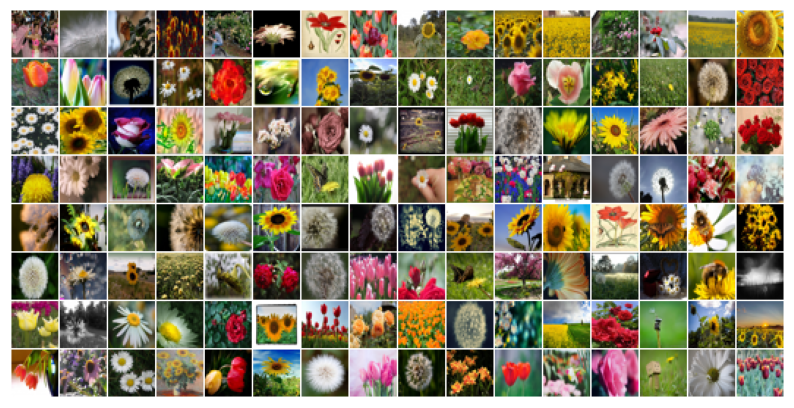

In [9]:
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

loader = get_dataloader(
    dataset_name=BaseConfig.DATASET,
    batch_size=128,
    device="cpu"
)

plt.figure(figsize=(10, 8), facecolor='white')

for b_image, _ in loader:
    b_image = inverse_transform(b_image)
    grid_img = make_grid(b_image / 255.0, nrow=16, padding=True, pad_value=1)
    plt.imshow(grid_img.cpu().permute(1, 2, 0))
    plt.axis("off")
    break

In [10]:
class SimpleDiffusion:
    def __init__(
        self,
        num_diffusion_timesteps=1000,
        img_shape=(3, 64, 64),
        device= "cpu",
    ):
        self.num_diffusion_timesteps = num_diffusion_timesteps
        self.img_shape = img_shape
        self.device = device
        self.initialize()

    def initialize(self):
        self.beta  = self.get_betas()
        self.alpha = 1 - self.beta

        self_sqrt_beta                       = torch.sqrt(self.beta)
        self.alpha_cumulative                = torch.cumprod(self.alpha, dim=0)
        self.sqrt_alpha_cumulative           = torch.sqrt(self.alpha_cumulative)
        self.one_by_sqrt_alpha               = 1. / torch.sqrt(self.alpha)
        self.sqrt_one_minus_alpha_cumulative = torch.sqrt(1 - self.alpha_cumulative)

    def get_betas(self):
        """linear schedule, proposed in original ddpm paper"""
        scale = 1000 / self.num_diffusion_timesteps
        beta_start = scale * 1e-4
        beta_end = scale * 0.02
        return torch.linspace(
            beta_start,
            beta_end,
            self.num_diffusion_timesteps,
            dtype=torch.float32,
            device=self.device,
        )

    """
    Performs the forward diffusion process.

    Args:
        x0: The initial input tensor (image).
        timesteps: A tensor of timesteps.

    Returns:
        A tuple containing the diffused sample and the noise added.
     """

    def forward_diffusion(self, x0: torch.Tensor, timesteps: torch.Tensor):
        eps = torch.randn_like(x0)

        batch_size = x0.shape[0]
        timesteps = timesteps.expand(batch_size)

        sqrt_alpha = self.sqrt_alpha_cumulative[timesteps].view(-1, 1, 1, 1)
        sqrt_one_minus_alpha = self.sqrt_one_minus_alpha_cumulative[timesteps].view(-1, 1, 1, 1)

        sample = sqrt_alpha * x0 + sqrt_one_minus_alpha * eps

        return sample, eps

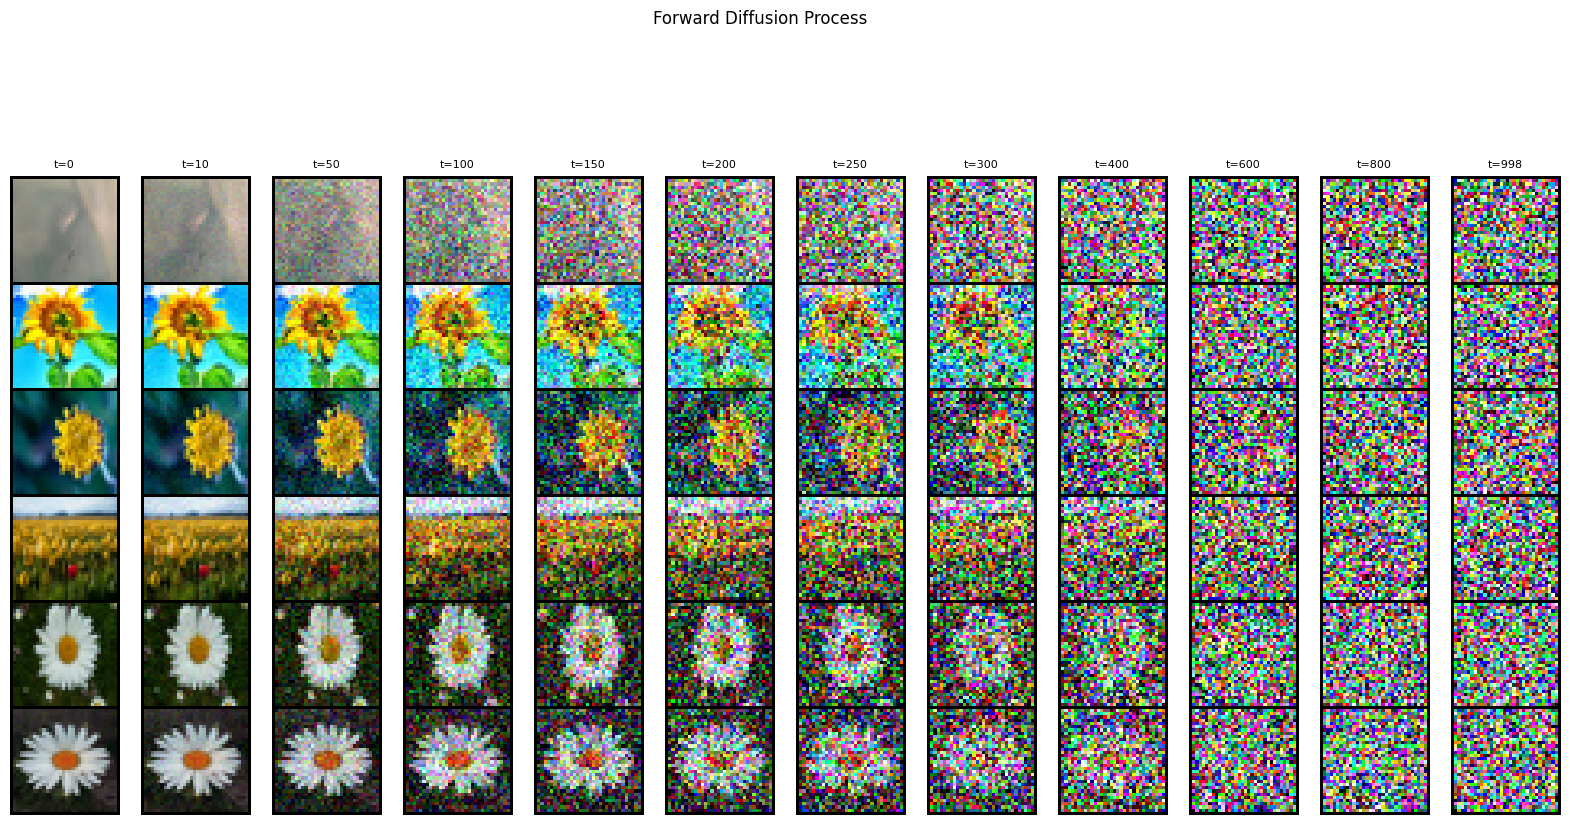

In [11]:
sd = SimpleDiffusion(num_diffusion_timesteps=TrainingConfig.TIMESTEPS, device="cpu")

loader = iter(
    get_dataloader(
        dataset_name=BaseConfig.DATASET,
        batch_size=6,
        device="cpu"
    )
)

x0s, _ = next(loader)

noisy_images = []
specific_timesteps = [0, 10, 50, 100, 150, 200, 250, 300, 400, 600, 800, 998]

for timestep in specific_timesteps:
    timestep = torch.as_tensor(timestep, dtype=torch.long)

    xts, _ = sd.forward_diffusion(x0s, timestep)
    xts    = inverse_transform(xts) / 255.0
    xts    = make_grid(xts, nrow=1, padding=1)

    noisy_images.append(xts)

_, ax = plt.subplots(1, len(noisy_images), figsize=(20, 12), facecolor='white')

for i, (timestep, noisy_sample) in enumerate(zip(specific_timesteps, noisy_images)):
    ax[i].imshow(noisy_sample.cpu().squeeze(0).permute(1, 2, 0))
    ax[i].set_title(f"t={timestep}", fontsize=8)
    ax[i].axis("off")
    ax[i].grid(False)

plt.suptitle("Forward Diffusion Process", y=0.9)
plt.axis("off")
plt.show()

In [13]:
!pip install -q torchmetrics

In [14]:
from torchmetrics import MeanMetric

def train_one_epoch(model, loader, sd, optimizer, scaler, loss_fn, epoch=20,
                   base_config=BaseConfig(), training_config=TrainingConfig()):

    loss_record = MeanMetric().to(base_config.DEVICE)
    model.train()

    with tqdm(total=len(loader), dynamic_ncols=True) as tq:
        tq.set_description(f"Train :: Epoch: {epoch}/{training_config.NUM_EPOCHS}")

        for x0s, _ in loader:
            tq.update(1)

            ts = torch.randint(low=1, high=training_config.TIMESTEPS, size=(x0s.shape[0],), device=base_config.DEVICE)
            xts, gt_noise = sd.forward_diffusion(x0s, ts)

            with amp.autocast():
                pred_noise = model(xts, ts).sample
                loss = loss_fn(gt_noise, pred_noise)

            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()

            scaler.step(optimizer)
            scaler.update()

            loss_value = loss.detach().item()
            loss_record.update(loss_value)

            tq.set_postfix_str(s=f"Loss: {loss_value}")

        mean_loss = loss_record.compute().item()

        tq.set_postfix_str(s=f"Epoch Loss: {mean_loss}")

    return mean_loss

In [15]:
!pip install -q Pillow

In [16]:
from PIL import Image
import numpy as np
import cv2

def frames2vid(frames, save_path, fps=30):
    """Converts a list of frames (numpy arrays) into a video file."""

    height, width, layers = frames[0].shape
    size = (width, height)

    out = cv2.VideoWriter(save_path, cv2.VideoWriter_fourcc(*'mp4v'), fps, size)
    for frame in frames:
        out.write(frame)
    out.release()

In [17]:
@torch.no_grad()
def reverse_diffusion(model, sd, timesteps=1000, img_shape=(3, 64, 64),
                      num_images=5, nrow=8, device="cpu", **kwargs):

    x = torch.randn((num_images, *img_shape), device=device)
    model.eval()

    if kwargs.get("generate_video", False):
        outs = []

    for time_step in tqdm(iterable=reversed(range(1, timesteps)),
                          total=timesteps-1, dynamic_ncols=False,
                          desc="Sampling :: ", position=0):

        ts = torch.ones(num_images, dtype=torch.long, device=device) * time_step
        z = torch.randn_like(x) if time_step > 1 else torch.zeros_like(x)

        predicted_noise = model(x, ts).sample

        sd.sqrt_alpha_cumulative[ts]
        beta_t                            = sd.beta[ts]
        one_by_sqrt_alpha_t               = sd.one_by_sqrt_alpha[ts]
        sqrt_one_minus_alpha_cumulative_t = sd.sqrt_one_minus_alpha_cumulative[ts]

        x = (
            one_by_sqrt_alpha_t
            * (x - (beta_t / sqrt_one_minus_alpha_cumulative_t) * predicted_noise)
            + torch.sqrt(beta_t) * z
        )

        if kwargs.get("generate_video", False):
            x_inv = inverse_transform(x).type(torch.uint8)
            grid = make_grid(x_inv, nrow=nrow, pad_value=255.0).to("cpu")
            ndarr = torch.permute(grid, (1, 2, 0)).numpy()[:, :, ::-1]
            outs.append(ndarr)

    if kwargs.get("generate_video", False):
        frames2vid(outs, kwargs['save_path'])
        display(Image.fromarray(outs[-1][:, :, ::-1]))
        return None

    else:
        x = inverse_transform(x).type(torch.uint8)
        grid = make_grid(x, nrow=nrow, pad_value=255.0).to("cpu")
        pil_image = TF.functional.to_pil_image(grid)
        pil_image.save(kwargs['save_path'], format=save_path[-3:].upper())
        display(pil_image)
        return None

In [19]:
!pip install -q diffusers
!pip install -q accelerate

In [20]:
from dataclasses import dataclass
import os

import torch
import torch.nn as nn
from torch.cuda import amp
from tqdm import tqdm
import gc

from accelerate import Accelerator
from diffusers import UNet2DModel

In [21]:
@dataclass
class ModelConfig:
    BASE_CH = 64
    BASE_CH_MULT = (1, 2, 4, 4)
    APPLY_ATTENTION = (False, True, True, False)
    DROPOUT_RATE = 0.1
    TIME_EMB_MULT = 4

model = UNet2DModel(
    in_channels             = TrainingConfig.IMG_SHAPE[0],
    out_channels            = TrainingConfig.IMG_SHAPE[0],
    block_out_channels      = [ModelConfig.BASE_CH * i for i in ModelConfig.BASE_CH_MULT],
    layers_per_block=2,
    down_block_types=(
        "DownBlock2D",
        "DownBlock2D",
        "DownBlock2D",
        "AttnDownBlock2D",
    ),
    up_block_types=(
        "AttnUpBlock2D",
        "UpBlock2D",
        "UpBlock2D",
        "UpBlock2D",
    ),
)

model.to(BaseConfig.DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=TrainingConfig.LR)

dataloader = get_dataloader(
    dataset_name  = BaseConfig.DATASET,
    batch_size    = TrainingConfig.BATCH_SIZE,
    device        = BaseConfig.DEVICE,
    pin_memory    = True,
    num_workers   = TrainingConfig.NUM_WORKERS,
)

loss_fn = nn.MSELoss()

sd = SimpleDiffusion(
    num_diffusion_timesteps = TrainingConfig.TIMESTEPS,
    img_shape               = TrainingConfig.IMG_SHAPE,
    device                  = BaseConfig.DEVICE,
)

scaler = amp.GradScaler()

  scaler = amp.GradScaler() # For mixed-precision training.


In [22]:
import os
from datetime import datetime

def setup_log_directory(config):
    """Sets up the log and checkpoint directories for the training run.
    Args:
        config: The configuration object containing the root log and checkpoint directories.
    Returns:
        Tuple[str, str]: The paths to the log and checkpoint directories.
    """

    os.makedirs(config.root_log_dir, exist_ok=True)
    os.makedirs(config.root_checkpoint_dir, exist_ok=True)

    timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")
    log_dir = os.path.join(config.root_log_dir, config.log_dir, timestamp)
    checkpoint_dir = os.path.join(config.root_checkpoint_dir, config.checkpoint_dir, timestamp)

    os.makedirs(log_dir, exist_ok=True)
    os.makedirs(checkpoint_dir, exist_ok=True)

    return log_dir, checkpoint_dir

In [23]:
total_epochs = TrainingConfig.NUM_EPOCHS + 1
log_dir, checkpoint_dir = setup_log_directory(config=BaseConfig())
generate_video = False
ext = ".mp4" if generate_video else ".png"

  with amp.autocast():


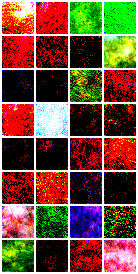

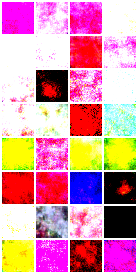

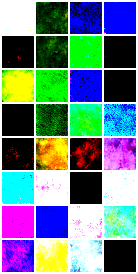

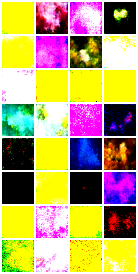

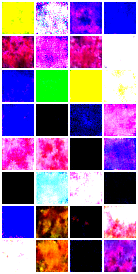

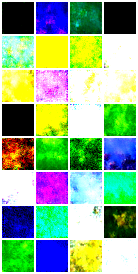

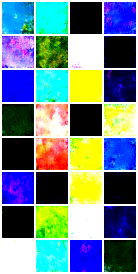

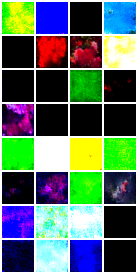

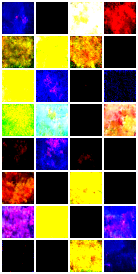

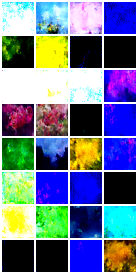

In [24]:
for epoch in range(1, total_epochs):
    torch.cuda.empty_cache()
    gc.collect()

    train_one_epoch(model, dataloader, sd, optimizer, scaler, loss_fn, epoch=epoch)

    if epoch % 2 == 0:
        save_path = os.path.join(log_dir, f"{epoch}{ext}")

        reverse_diffusion(model, sd, timesteps=TrainingConfig.TIMESTEPS,
                          num_images=32, generate_video=generate_video, save_path=save_path,
                          img_shape=TrainingConfig.IMG_SHAPE, device=BaseConfig.DEVICE, nrow=4,
        )

        checkpoint_dict = {
            "opt": optimizer.state_dict(),
            "scaler": scaler.state_dict(),
            "model": model.state_dict()
        }
        torch.save(checkpoint_dict, os.path.join(checkpoint_dir, "ckpt.pt"))
        del checkpoint_dict

In [25]:
model = UNet2DModel(
    in_channels             = TrainingConfig.IMG_SHAPE[0],
    out_channels            = TrainingConfig.IMG_SHAPE[0],
    block_out_channels      = [ModelConfig.BASE_CH * i for i in ModelConfig.BASE_CH_MULT],
    layers_per_block=2,
    down_block_types=(
        "DownBlock2D",
        "DownBlock2D",
        "DownBlock2D",
        "AttnDownBlock2D",
    ),
    up_block_types=(
        "AttnUpBlock2D",
        "UpBlock2D",
        "UpBlock2D",
        "UpBlock2D",
    ),
)

model.load_state_dict(torch.load(os.path.join(checkpoint_dir, "ckpt.pt"), map_location='cpu')['model'])

model.to(BaseConfig.DEVICE)

sd = SimpleDiffusion(
    num_diffusion_timesteps = TrainingConfig.TIMESTEPS,
    img_shape               = TrainingConfig.IMG_SHAPE,
    device                  = BaseConfig.DEVICE,
)

log_dir = "inference_results"

In [26]:
log_dir = "inference_results"
os.makedirs(log_dir, exist_ok=True)

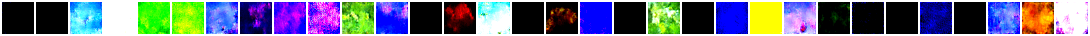

inference_results/20261005-203125.mp4


In [27]:
generate_video = True

ext = ".mp4" if generate_video else ".png"
filename = f"{datetime.now().strftime('%Y%m%d-%H%M%S')}{ext}"

save_path = os.path.join(log_dir, filename)

reverse_diffusion(
    model,
    sd,
    num_images=32,
    generate_video=generate_video,
    save_path=save_path,
    timesteps=1000,
    img_shape=TrainingConfig.IMG_SHAPE,
    device=BaseConfig.DEVICE,
    nrow=32,
)

print(save_path)

In [28]:
!pip install -q torch-fidelity diffusers
import os, glob, json, numpy as np, torch, torchvision, kagglehub
import torchvision.transforms as T
from tqdm.auto import tqdm
from torchvision.utils import save_image
from diffusers import UNet2DModel
from torchmetrics.image.fid import FrechetInceptionDistance
from torchmetrics.image.kid import KernelInceptionDistance

DEV = torch.device("cuda")
OUT = "/kaggle/working/baseline_asis"; os.makedirs(OUT, exist_ok=True)
N_GEN, SEED, BS = 2000, 0, 250

model = UNet2DModel(in_channels=3, out_channels=3, block_out_channels=[64, 128, 256, 256],
    layers_per_block=2,
    down_block_types=("DownBlock2D", "DownBlock2D", "DownBlock2D", "AttnDownBlock2D"),
    up_block_types=("AttnUpBlock2D", "UpBlock2D", "UpBlock2D", "UpBlock2D"))
if os.path.exists(f"{OUT}/model.pt"):
    sdict = torch.load(f"{OUT}/model.pt", map_location="cpu")
else:
    ck = sorted(glob.glob("/kaggle/working/Logs_Checkpoints/checkpoints/**/ckpt.pt", recursive=True))[-1]
    sdict = torch.load(ck, map_location="cpu")["model"]
    torch.save(sdict, f"{OUT}/model.pt")
model.load_state_dict(sdict); model.to(DEV).eval()

beta = torch.linspace(1e-4, 0.02, 1000, device=DEV)
alpha = 1 - beta
a_bar = torch.cumprod(alpha, 0)
one_by_sqrt_alpha = 1 / torch.sqrt(alpha)
sqrt_1m_abar = torch.sqrt(1 - a_bar)

@torch.no_grad()
def sample(n, seed, T_steps=1000):
    g = torch.Generator(device=DEV).manual_seed(seed); outs = []
    for s in range(0, n, BS):
        b = min(BS, n - s)
        x = torch.randn((b, 3, 32, 32), device=DEV, generator=g)
        for t in tqdm(reversed(range(1, T_steps)), total=T_steps-1, desc=f"batch {s//BS+1}/{(n+BS-1)//BS}", leave=False):
            ts = torch.full((b,), t, dtype=torch.long, device=DEV)
            z = torch.randn(x.shape, device=DEV, generator=g) if t > 1 else torch.zeros_like(x)
            eps = model(x, ts).sample
            x = one_by_sqrt_alpha[t] * (x - (beta[t] / sqrt_1m_abar[t]) * eps) + torch.sqrt(beta[t]) * z
        x = torch.nan_to_num(x, nan=0.0).clamp(-1, 1)
        outs.append(((x + 1) / 2 * 255).round().to(torch.uint8).cpu())
    return torch.cat(outs)

path = kagglehub.dataset_download("alxmamaev/flowers-recognition")
real_tf = T.Compose([T.ToTensor(), T.Resize((32, 32), interpolation=T.InterpolationMode.BICUBIC, antialias=True)])
real_ds = torchvision.datasets.ImageFolder(root=path, transform=real_tf)
real_u8 = (torch.stack([real_ds[i][0] for i in range(len(real_ds))]).clamp(0, 1) * 255).round().to(torch.uint8)
print("real:", real_u8.shape)

def fid_kid(a_u8, b_u8):
    fid = FrechetInceptionDistance(feature=2048).to(DEV)
    kid = KernelInceptionDistance(subset_size=min(1000, len(a_u8), len(b_u8))).to(DEV)
    for x, flag in ((a_u8, True), (b_u8, False)):
        for i in range(0, len(x), 500):
            xb = x[i:i+500].to(DEV); fid.update(xb, real=flag); kid.update(xb, real=flag)
    km, ks = kid.compute()
    return fid.compute().item(), km.item(), ks.item()

gen = sample(N_GEN, SEED)
np.save(f"{OUT}/samples_seed{SEED}.npy", gen.numpy())
save_image(gen[:64].float() / 255, f"{OUT}/samples_grid.png", nrow=8)

f, km, ks = fid_kid(real_u8, gen)
perm = torch.randperm(len(real_u8), generator=torch.Generator().manual_seed(0)); h = len(real_u8) // 2
ff, fk, _ = fid_kid(real_u8[perm[:h]], real_u8[perm[h:2*h]])
res = {"n_gen": N_GEN, "seed": SEED, "fid": f, "kid": km, "kid_std": ks, "floor_fid": ff, "floor_kid": fk}
json.dump(res, open(f"{OUT}/results_seed{SEED}.json", "w"), indent=2)
print(json.dumps(res, indent=2))

real: torch.Size([4317, 3, 32, 32])


> **Note:** the scoring part of this cell failed on Kaggle (torch-fidelity was installed after torchmetrics was imported). The 2,000 images were saved before the error and are scored in `02_score_reference.ipynb`.